# **Standarization**
Standardization is a feature-scaling technique that transforms numerical data so that it has a mean of approximately 0 and a standard deviation of approximately 1. It only change the scale of the data without changing the distribution of data. It is also called z-score.

**Standardization uses this formula:**

z = (x - μ) / σ

-  x: The value you want to standardize
-  μ (mu): The mean of the distribution
-  σ (sigma): The standard deviation of the distribution


In [116]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [117]:
df = pd.read_csv("data/titanic.csv", usecols=["Survived", "Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"])

In [118]:
df.isna().sum()

Survived      0
Pclass        0
Sex           0
Age         177
SibSp         0
Parch         0
Fare          0
Embarked      2
dtype: int64

In [119]:
df["Age"] = df["Age"].fillna(df["Age"].mean())

In [120]:
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

In [121]:
df.isna().sum()

Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64

In [122]:
df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


In [123]:
# split the data into X, y

X = df.drop(columns=["Survived"])
y = df["Survived"]

In [124]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [125]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

num_col = ["Pclass", "Age", "SibSp", "Parch", "Fare"]

scaler.fit(X_train[num_col])

,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [126]:
X_train[num_col] = scaler.transform(X_train[num_col])
X_test[num_col] = scaler.transform(X_test[num_col])

In [127]:
X_train

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
331,-1.614136,male,1.229207,-0.470722,-0.479342,-0.078684,S
733,-0.400551,male,-0.503505,-0.470722,-0.479342,-0.377145,S
382,0.813034,male,0.189580,-0.470722,-0.479342,-0.474867,S
704,0.813034,male,-0.272477,0.379923,-0.479342,-0.476230,S
813,0.813034,female,-1.812666,2.931860,2.048742,-0.025249,S
...,...,...,...,...,...,...,...
106,0.813034,female,-0.657524,-0.470722,-0.479342,-0.480162,S
270,-1.614136,male,0.012390,-0.470722,-0.479342,-0.030545,S
860,0.813034,male,0.882665,1.230569,-0.479342,-0.355804,S
435,-1.614136,female,-1.196590,0.379923,2.048742,1.683201,S


In [128]:
import warnings 
warnings.filterwarnings("ignore")

In [129]:
# checking the mean and standard deviation before and after scalling

def check(col_name):
    print("\nBefore Scalling the", col_name)
    print("mean :", int(df[col_name].mean()))
    print("std :", int(df[col_name].std()))
    print("\nAfter Scalling the", col_name)
    print("mean :", int(X_train[col_name].mean()))
    print("std :", int(X_train[col_name].std()))
    
    fig, axes = plt.subplots(1, 2, figsize=(12, 3))
    sns.kdeplot(data=df, x=col_name, ax=axes[0])
    axes[0].set_title("Distribution before scalling")
    
    sns.kdeplot(data=X_train, x=col_name, ax=axes[1])
    axes[1].set_title("Distribution after scalling")
    fig.show()


Before Scalling the Age
mean : 29
std : 13

After Scalling the Age
mean : 0
std : 1


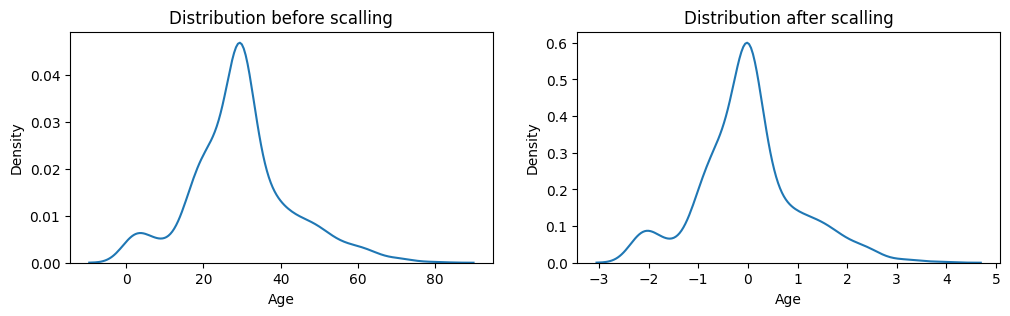

In [130]:
check("Age")


Before Scalling the Fare
mean : 32
std : 49

After Scalling the Fare
mean : 0
std : 1


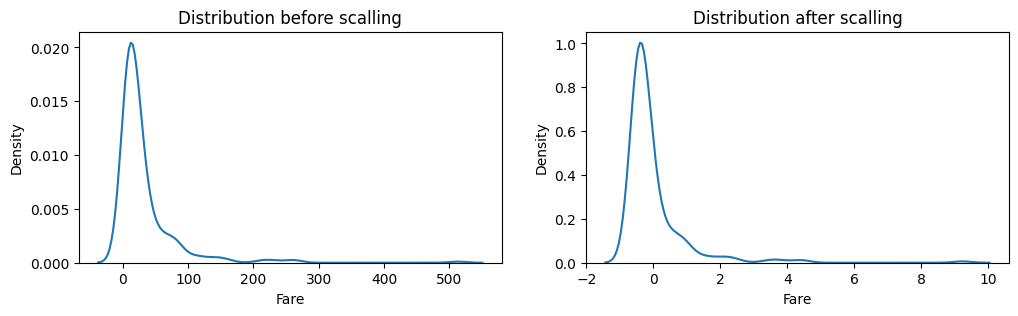

In [131]:
check("Fare")

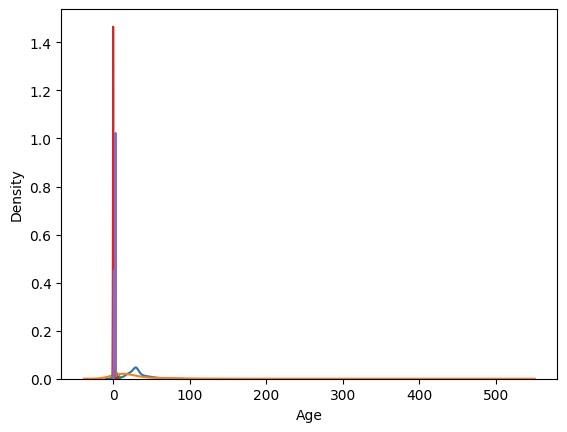

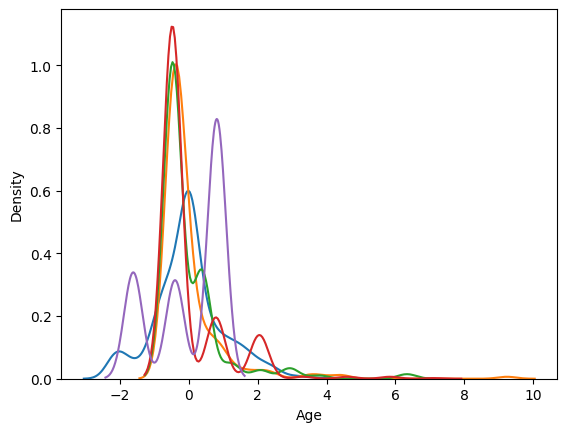

In [132]:
sns.kdeplot(df["Age"])
sns.kdeplot(df["Fare"])
sns.kdeplot(df["SibSp"])
sns.kdeplot(df["Parch"])
sns.kdeplot(df["Pclass"])
plt.show()


sns.kdeplot(X_train["Age"])
sns.kdeplot(X_train["Fare"])
sns.kdeplot(X_train["SibSp"])
sns.kdeplot(X_train["Parch"])
sns.kdeplot(X_train["Pclass"])
plt.show()